# Лабораторная работа 1. Анализ сложности алгоритмов

**Опора:** лекции 1–2.

Реализовать требуется только три функции. Генерация массивов, подсчёт обращений
к элементам, измерение времени и графики уже готовы и лежат в пакете `labkit`
рядом с ноутбуком.

Эксперименты запускаются после того, как пройдены тесты.

In [2]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

Режим: быстрый | размеры массивов: [10, 100, 1000, 10000]


/home/klyce/Documents/DSA_IDU_26/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Задача 1. Линейный поиск

Найти в массиве позицию заданного значения, просматривая элементы подряд.

- **Вход:** массив целых чисел и искомое значение.
- **Выход:** индекс любого вхождения значения; если значения нет — `-1`.

In [4]:
def linear_search(arr, target):
    """Индекс любого вхождения target в arr или -1, если его нет."""
    # TODO: реализовать линейный поиск
    for i in range(len(arr)):
        if arr[i] == target:
            return i
    return -1
    raise NotImplementedError("linear_search")

In [5]:
lk.check_search(linear_search, "Линейный поиск")

Линейный поиск
  [ok]   массив длины 0, поиск 5
    Input: {'arr': [], 'target': 5}
    Output: -1
    Expected: -1
  [ok]   массив длины 1, поиск 5
    Input: {'arr': [5], 'target': 5}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 1, поиск 10
    Input: {'arr': [5], 'target': 10}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск 1
    Input: {'arr': [4, 1, 3, 2], 'target': 1}
    Output: 1
    Expected: {'любой из индексов': [1]}
  [ok]   массив длины 4, поиск 4
    Input: {'arr': [4, 1, 3, 2], 'target': 4}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 4, поиск 3
    Input: {'arr': [4, 1, 3, 2], 'target': 3}
    Output: 2
    Expected: {'любой из индексов': [2]}
  [ok]   массив длины 4, поиск 100
    Input: {'arr': [4, 1, 3, 2], 'target': 100}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск -5
    Input: {'arr': [5, -10, 0, -5], 'target': -5}
    Output: 3
    Expected: {'любой из индексов': [3]}

## Задача 2. Двоичный поиск

Решить ту же задачу на массиве, отсортированном по неубыванию, сокращая
рассматриваемый участок вдвое на каждом шаге.

- **Вход:** отсортированный массив целых чисел и искомое значение.
- **Выход:** индекс любого вхождения значения; если значения нет — `-1`.
- **Требование:** за одну итерацию значение из массива читается один раз.

In [23]:
def binary_search(arr, target):
    """Индекс любого вхождения target в отсортированном arr или -1."""
    # TODO: реализовать двоичный поиск

    lower_bound = 0
    upper_bound = len(arr) - 1

    while lower_bound <= upper_bound:
        cursor = round((lower_bound + upper_bound) / 2)
        element = arr[cursor]

        if element == target:
            return cursor
        elif element > target:
            upper_bound = cursor - 1
        else:
            lower_bound = cursor + 1

    return -1

    raise NotImplementedError("binary_search")

In [24]:
lk.check_search(binary_search, "Двоичный поиск", expect_logarithmic=True)

Двоичный поиск
  [ok]   массив длины 0, поиск 5
    Input: {'arr': [], 'target': 5}
    Output: -1
    Expected: -1
  [ok]   массив длины 1, поиск 5
    Input: {'arr': [5], 'target': 5}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 1, поиск 10
    Input: {'arr': [5], 'target': 10}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск 1
    Input: {'arr': [1, 2, 3, 4], 'target': 1}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 4, поиск 4
    Input: {'arr': [1, 2, 3, 4], 'target': 4}
    Output: 3
    Expected: {'любой из индексов': [3]}
  [ok]   массив длины 4, поиск 3
    Input: {'arr': [1, 2, 3, 4], 'target': 3}
    Output: 2
    Expected: {'любой из индексов': [2]}
  [ok]   массив длины 4, поиск 100
    Input: {'arr': [1, 2, 3, 4], 'target': 100}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск -5
    Input: {'arr': [-10, -5, 0, 5], 'target': -5}
    Output: 1
    Expected: {'любой из индексов': [1]}

## Задача 3. Палиндром

Определить, читается ли строка одинаково слева направо и справа налево.

- **Вход:** строка.
- **Выход:** `True`, если строка — палиндром, иначе `False`.
- **Требования:** решение рекурсивное; циклы и срезы запрещены; сравнение идёт
  с двух концов строки к середине.

```text
Вход:  "level"      Выход: True
Вход:  "algorithm"  Выход: False
Вход:  ""           Выход: True
```

In [16]:
def is_palindrome(text, left=0, right=None):
    """True, если text читается одинаково в обе стороны."""
    # TODO: реализовать рекурсивно, без циклов и срезов
    if right is None:
        right = -1

    if len(text) < 2 or left > len(text) / 2:
        return True

    if text[left] != text[right]:
        return False
    else:
        return is_palindrome(text, left + 1, right - 1)

    raise NotImplementedError("is_palindrome")

In [17]:
lk.check_palindrome(is_palindrome)

Палиндром
  [ok]   проверка палиндрома
    Input: {'text': ''}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'a'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'aa'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'ab'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': 'aba'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'abba'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'abc'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': 'level'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'algorithm'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': '123454321'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': '123456

In [26]:
SEARCHES = {"Линейный поиск": linear_search, "Двоичный поиск": binary_search}
search_cases = lk.search_cases_table(SEARCHES)

Поиск: время и обращения: 100%|██████████| 104/104 [00:01<00:00, 92.48опыт/s]


## Эксперимент 1. Неуспешный поиск

Массив содержит `0, …, n−1`, искомое значение — `n`.

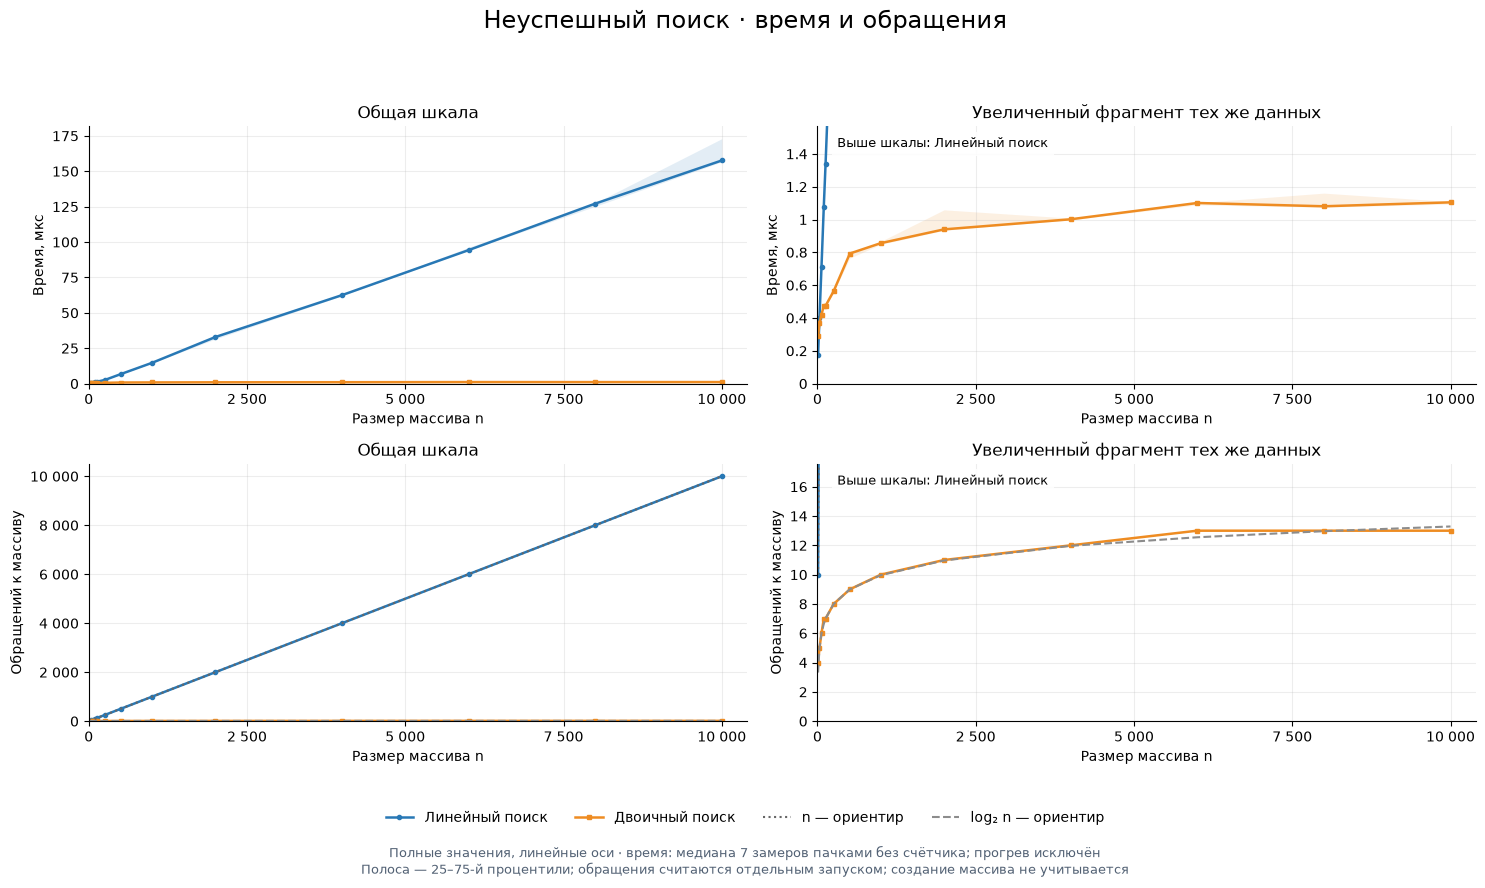

In [28]:
lk.plot_search_overview(search_cases);

## Эксперимент 2. Позиция искомого элемента

Один отсортированный массив, три случая: значение в начале, в середине
и в конце. Середина — индекс `(n−1)//2`. Случай отсутствующего элемента
рассмотрен в предыдущем эксперименте.

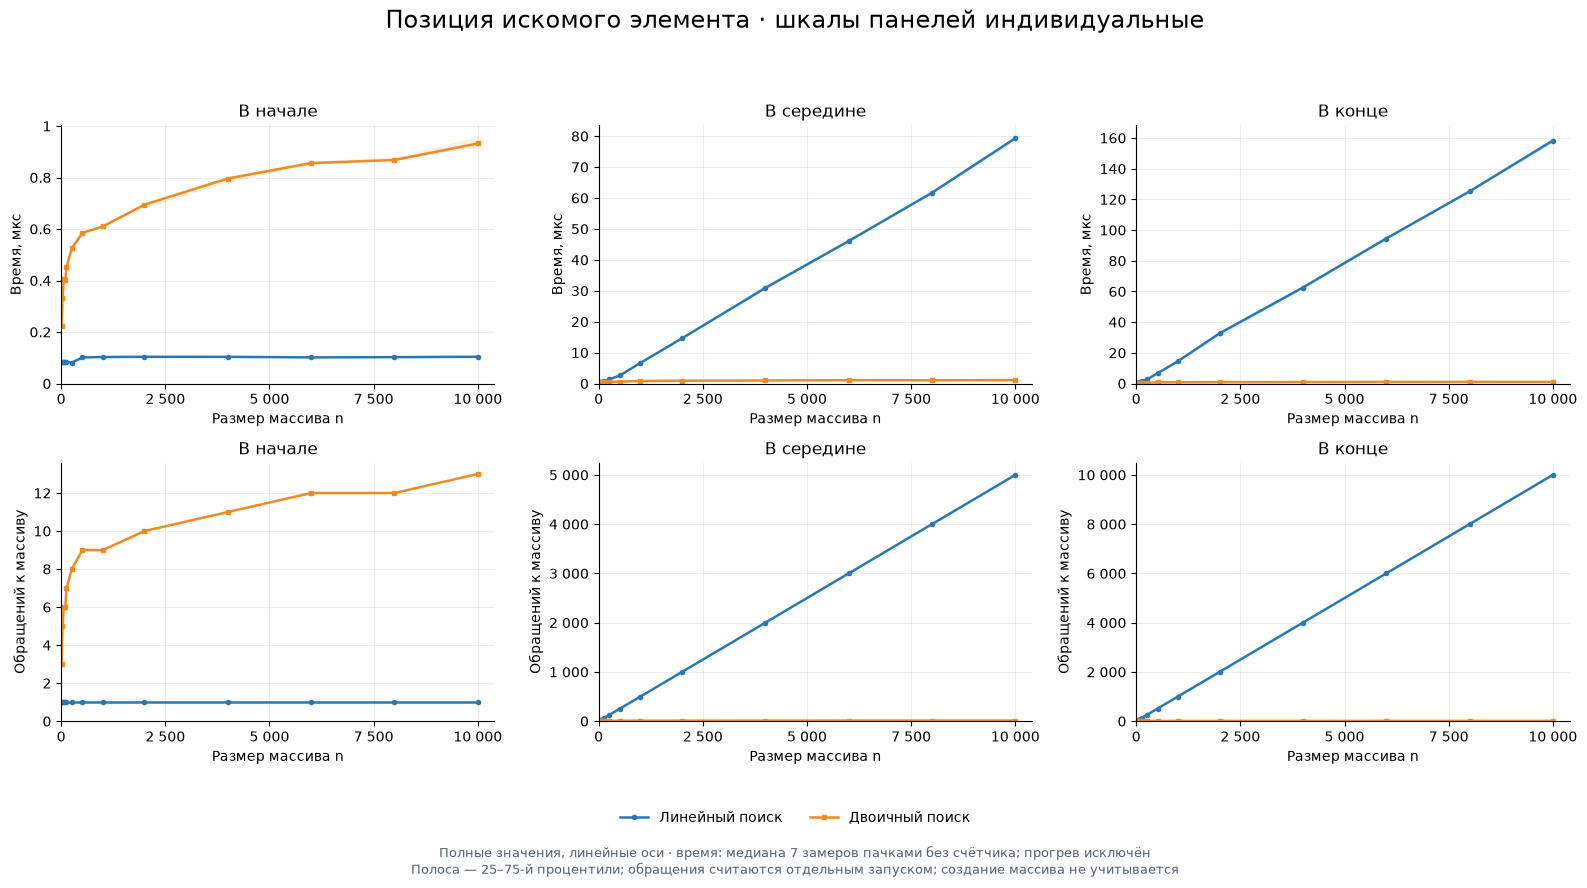

In [27]:
lk.plot_search_positions(search_cases);

## Самостоятельные выводы

1. Почему при расположении цели в начале массива время линейного поиска почти не зависит от размера массива, а двоичный поиск всё равно выполняет несколько шагов?
- т.к. линейный поиск проверяет элементы последовательно, то находящийся в начале элемент будет всегда проверен первым и найден сразу, давая O(1) в этом случае. Для двоичного поиска наоборот: первый элемент - это один из худших случаев, при котором ему придётся выполнить все log(n) проверок, т.к. лежит на дне "дерева"
2. Почему середина массива является особым случаем для двоичного поиска? Всегда ли элемент «в середине» будет найден за первое обращение?
- элемент в середине особенный т.к. двоичный поиск первой берёт на проверку середину. При этом середину я реализовал как round((upper - lower) / 2), что значит, при нечётном кол-ве элементов серединный элемент будет всенда проверен, а при чётном будет проверен правый из серединных. Из-за этого если ищем левый серединный элемент, то придётся пройти log(n). При середине заданной как (n-1)//2 из условия, нечётный случай такой-же, а при чётном кол-ве элементов - выбирается левый, а правый - требует  loп(n) поисков
3. Почему случаи «элемент в конце» и «элемент отсутствует» близки для линейного поиска? Чем обработка этих случаев отличается у двоичного поиска?
- для линейного - в обоих случаях придётся проверить каждый элемент, чтобы либо найти последний, либо убедиться что такого нет. Для двоичного поиска - последний элемент тоже худший случай, но из-за того, что лучший случай - log(n) вместо n - это не сильно важно; при этом отсутствующий элемент может так же потребовать как все log(n) поисков (например меньше минимального элемента) так и найтись за один элемент до этого если дерево не полное.
4. Почему двоичный поиск требует упорядоченных данных? Что именно перестаёт быть верным без этого условия?
- данные должны быть упорядоченны, т.к. для его реализации требуется, чтобы мы могли отрезать половину элементов за каждый ход, что основывается на знании, что по одну сторону проверяемого элемента - ни один не больше данного, а по другую - ни один не меньше.
5. Каковы базовый случай и рекурсивный переход у проверки палиндрома? Почему каждый переход приближает алгоритм к завершению?
- базовый случай - O(n) - т.к. операции растут линейно с количеством букв. В худшем случаем мы проверяем n/2 + 1 если слово - палиндром, непалиндромы всегда лучше, т.к. выбрасывают из проверки раньше. Рекурсивный переход линеен, всегда отбрасывает 2 буквы. Каждый переход приближает к завершению потому что на проверку поступают всё меньшие слова, и любые слова достигнувшие длины в меньше 2 букв - палиндромы по условию.